**Не зафиксировал объективно, повлияля ли видеокарта на скорость обчения. Поэтому лучше перед выполнением ячеек всё же переключиться на графический процессор.**

# **Практическое занятие: RNN, LSTM и GRU**

В этом блокноте мы проведём эксперименты с рекуррентными сетями, чтобы на практике увидеть, как они справляются с долгосрочными зависимостями и как LSTM/GRU решают проблему затухающих градиентов. Мы используем PyTorch и Google Colab.

**План практики:**
1. **Adding problem** – синтетическая задача, требующая запоминания информации на большом расстоянии. Сравним vanilla RNN, LSTM и GRU, визуализируем градиенты.
2. **Классификация тональности на русском языке** – используем датасет RuSentiment, построим BiLSTM, сравним однонаправленную и двунаправленную модели, визуализируем скрытые состояния через t-SNE.

👉 *Инструкция:* Запускайте ячейки последовательно, меняйте гиперпараметры, где предложено, и отвечайте на вопросы для интерпретации.

## **1. Установка и импорт библиотек**

In [1]:
!pip install -q datasets transformers scikit-learn matplotlib seaborn

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')

# Для воспроизводимости
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## **2. Эксперимент 1: Adding problem (задача на долгосрочные зависимости)**

**Описание задачи:** Даётся последовательность случайных чисел $x_1, \dots, x_T$ (обычно T=100) и два индекса $i$ и $j$ (первый в первой половине, второй – во второй). Цель – рассчитать сумму $x_i + x_j$. Модель должна запомнить значения на больших расстояниях.

Мы сравним три модели: **vanilla RNN**, **LSTM**, **GRU**. Будем отслеживать:
- потери на валидации
- нормы градиентов для разных шагов времени (чтобы увидеть затухание)

Здесь формируются numpy вектора на выходе.

In [3]:
def generate_adding_problem_data(num_samples, seq_len=100):
    """
    Генерирует синтетический датасет для adding problem.
    Возвращает: X (num_samples, seq_len, 2) – два канала: значение и индикатор позиции,
                y (num_samples) – сумма двух выбранных чисел.
    """
    X = np.random.uniform(0, 1, (num_samples, seq_len, 2)).astype(np.float32)
    y = np.zeros((num_samples,), dtype=np.float32)
    for i in range(num_samples):
        # выбираем случайные индексы: первый в первой половине, второй – во второй
        idx1 = np.random.randint(0, seq_len // 2)
        idx2 = np.random.randint(seq_len // 2, seq_len)
        X[i, idx1, 1] = 1.0
        X[i, idx2, 1] = 1.0
        y[i] = X[i, idx1, 0] + X[i, idx2, 0]
    return X, y

# Генерируем train и val
seq_len = 100
train_X, train_y = generate_adding_problem_data(5000, seq_len)
val_X, val_y = generate_adding_problem_data(1000, seq_len)

print(f'Train shape: {train_X.shape}, Val shape: {val_X.shape}')

Train shape: (5000, 100, 2), Val shape: (1000, 100, 2)


Здесь из numpy векторов преобразование в тензоры pytorch и j,]trns lkz elj,cndf gjkextybz byajhvfwbb/

In [4]:
class AddingDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y).unsqueeze(1)  # для MSE функция в PyTorch, которая добавляет новое измерение размером 1 к тензору в указанной позиции (индекс измерения)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = AddingDataset(train_X, train_y)
val_dataset = AddingDataset(val_X, val_y)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

Построение классической рекуррентной нейросети

In [5]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Если batch_first = True, то входные и выходные тензоры имеют форму (batch_size, seq_len, input_size)
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.rnn(x)  # out: (batch, seq_len, hidden)
        out = self.fc(out[:, -1, :])  # используем последний скрытый
        return out



In [6]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out



In [7]:
class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

Реализация цикла обучения одной сети. Запоминает нормы градиентов

In [8]:
def train_model(model, train_loader, val_loader, epochs=20, lr=0.001, clip=1.0):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    grad_norms = []  # для отслеживания норм градиентов (по эпохам)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            # Обрезка градиентов
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            # Сохраняем норму градиентов для анализа
            total_norm = 0.0
            for p in model.parameters():
                if p.grad is not None:
                    param_norm = p.grad.data.norm(2)
                    total_norm += param_norm.item() ** 2
            total_norm = total_norm ** 0.5
            grad_norms.append(total_norm)
            optimizer.step()
            total_loss += loss.item()
        train_losses.append(total_loss / len(train_loader))

        # Валидация
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch)
                loss = criterion(pred, y_batch)
                val_loss += loss.item()
        val_losses.append(val_loss / len(val_loader))
        if (epoch+1) % 5 == 0:
            print(f'Epoch {epoch+1}: train_loss={train_losses[-1]:.4f}, val_loss={val_losses[-1]:.4f}')

    return train_losses, val_losses, grad_norms

Собственно обучение трёх сетей.
Осторожно! Работает долго.

In [9]:
input_size = 2
hidden_size = 128
output_size = 1
epochs = 30

print("Training Vanilla RNN...")
rnn_model = VanillaRNN(input_size, hidden_size, output_size)
rnn_train_loss, rnn_val_loss, rnn_grads = train_model(rnn_model, train_loader, val_loader, epochs=epochs)

print("\nTraining LSTM...")
lstm_model = LSTMModel(input_size, hidden_size, output_size)
lstm_train_loss, lstm_val_loss, lstm_grads = train_model(lstm_model, train_loader, val_loader, epochs=epochs)

print("\nTraining GRU...")
gru_model = GRUModel(input_size, hidden_size, output_size)
gru_train_loss, gru_val_loss, gru_grads = train_model(gru_model, train_loader, val_loader, epochs=epochs)

Training Vanilla RNN...
Epoch 5: train_loss=0.1684, val_loss=0.1703
Epoch 10: train_loss=0.1696, val_loss=0.1735
Epoch 15: train_loss=0.1673, val_loss=0.1711
Epoch 20: train_loss=0.1692, val_loss=0.1712
Epoch 25: train_loss=0.1679, val_loss=0.1701
Epoch 30: train_loss=0.1675, val_loss=0.1704

Training LSTM...
Epoch 5: train_loss=0.1686, val_loss=0.1747
Epoch 10: train_loss=0.1675, val_loss=0.1701
Epoch 15: train_loss=0.1682, val_loss=0.1709
Epoch 20: train_loss=0.1683, val_loss=0.1697
Epoch 25: train_loss=0.1682, val_loss=0.1701
Epoch 30: train_loss=0.1680, val_loss=0.1757

Training GRU...
Epoch 5: train_loss=0.1678, val_loss=0.1690
Epoch 10: train_loss=0.1684, val_loss=0.1732
Epoch 15: train_loss=0.1667, val_loss=0.1697
Epoch 20: train_loss=0.1663, val_loss=0.1712
Epoch 25: train_loss=0.1658, val_loss=0.1689
Epoch 30: train_loss=0.1670, val_loss=0.1718


### **2.1. Визуализация результатов**

В нормах градиентов итерация - это эпоха + номер батча внутри эпохи.

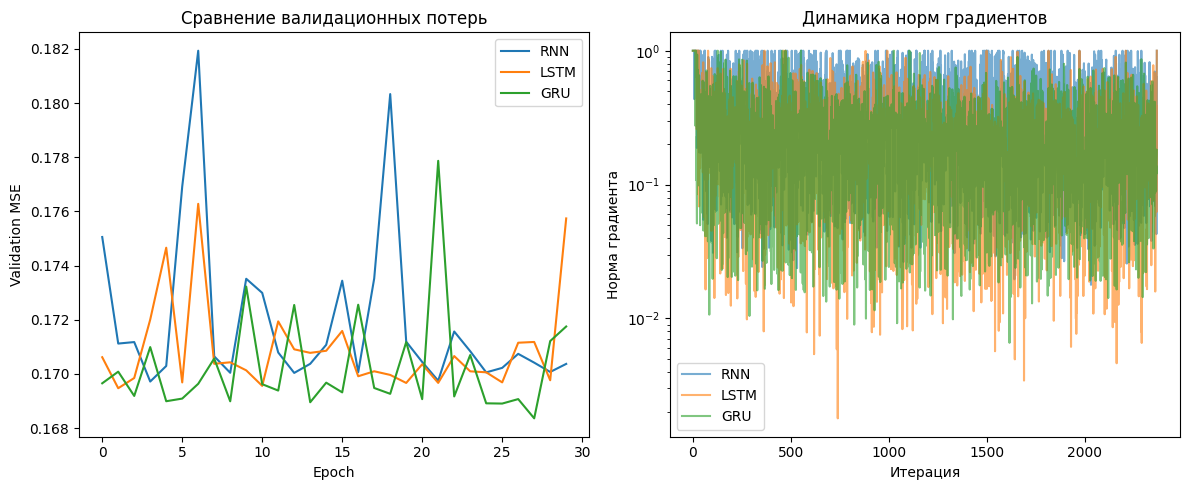

In [10]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(rnn_val_loss, label='RNN')
plt.plot(lstm_val_loss, label='LSTM')
plt.plot(gru_val_loss, label='GRU')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.legend()
plt.title('Сравнение валидационных потерь')

plt.subplot(1,2,2)
plt.plot(rnn_grads[:len(rnn_grads)], label='RNN', alpha=0.6)
plt.plot(lstm_grads[:len(lstm_grads)], label='LSTM', alpha=0.6)
plt.plot(gru_grads[:len(gru_grads)], label='GRU', alpha=0.6)
plt.xlabel('Итерация')
plt.ylabel('Норма градиента')
plt.yscale('log')
plt.legend()
plt.title('Динамика норм градиентов')
plt.tight_layout()
plt.show()

Теоретически надо было бы построить график такого плана:

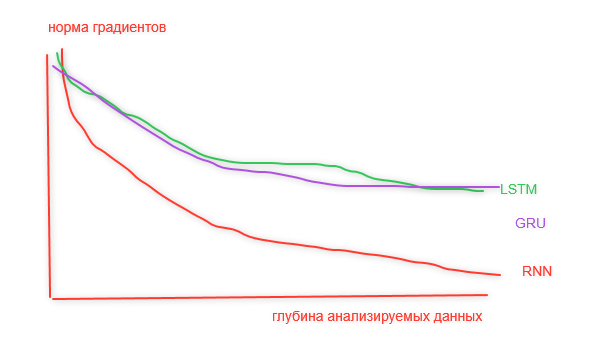

Training Vanilla RNN (seq_len=200)...
Epoch 5: train_loss=0.1684, val_loss=0.1863
Epoch 10: train_loss=0.1637, val_loss=0.1997
Epoch 15: train_loss=0.1625, val_loss=0.1867
Epoch 20: train_loss=0.1642, val_loss=0.1865
Epoch 25: train_loss=0.1629, val_loss=0.1873
Epoch 30: train_loss=0.1659, val_loss=0.1857

Training LSTM (seq_len=200)...
Epoch 5: train_loss=0.1660, val_loss=0.1871
Epoch 10: train_loss=0.1641, val_loss=0.1891
Epoch 15: train_loss=0.1644, val_loss=0.1849
Epoch 20: train_loss=0.1624, val_loss=0.1852
Epoch 25: train_loss=0.1627, val_loss=0.1850
Epoch 30: train_loss=0.1625, val_loss=0.1849

Training GRU (seq_len=200)...
Epoch 5: train_loss=0.1647, val_loss=0.1861
Epoch 10: train_loss=0.1631, val_loss=0.1847
Epoch 15: train_loss=0.1637, val_loss=0.1849
Epoch 20: train_loss=0.1620, val_loss=0.1858
Epoch 25: train_loss=0.1624, val_loss=0.1845
Epoch 30: train_loss=0.1620, val_loss=0.1861


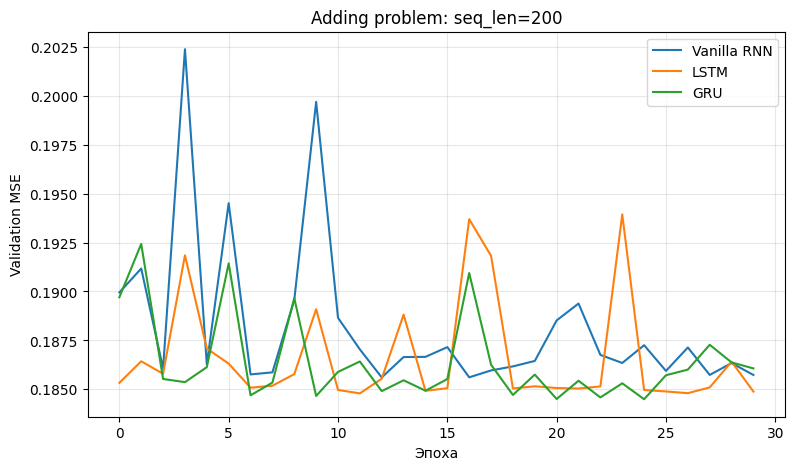

Минимальная validation MSE — RNN: 0.1856; LSTM: 0.1848; GRU: 0.1845


In [11]:
# Повторяем Adding problem с последовательностями длины 200
seq_len_200 = 200
train_X_200, train_y_200 = generate_adding_problem_data(5000, seq_len_200)
val_X_200, val_y_200 = generate_adding_problem_data(1000, seq_len_200)

train_dataset_200 = AddingDataset(train_X_200, train_y_200)
val_dataset_200 = AddingDataset(val_X_200, val_y_200)
train_loader_200 = DataLoader(train_dataset_200, batch_size=64, shuffle=True)
val_loader_200 = DataLoader(val_dataset_200, batch_size=64, shuffle=False)

# Параметры совпадают с экспериментом для seq_len=100
input_size_200 = 2
hidden_size_200 = 128
output_size_200 = 1
epochs_200 = 30

print("Training Vanilla RNN (seq_len=200)...")
rnn_model_200 = VanillaRNN(input_size_200, hidden_size_200, output_size_200)
rnn_train_loss_200, rnn_val_loss_200, rnn_grads_200 = train_model(
    rnn_model_200, train_loader_200, val_loader_200, epochs=epochs_200
)

print("\nTraining LSTM (seq_len=200)...")
lstm_model_200 = LSTMModel(input_size_200, hidden_size_200, output_size_200)
lstm_train_loss_200, lstm_val_loss_200, lstm_grads_200 = train_model(
    lstm_model_200, train_loader_200, val_loader_200, epochs=epochs_200
)

print("\nTraining GRU (seq_len=200)...")
gru_model_200 = GRUModel(input_size_200, hidden_size_200, output_size_200)
gru_train_loss_200, gru_val_loss_200, gru_grads_200 = train_model(
    gru_model_200, train_loader_200, val_loader_200, epochs=epochs_200
)

plt.figure(figsize=(9, 5))
plt.plot(rnn_val_loss_200, label='Vanilla RNN')
plt.plot(lstm_val_loss_200, label='LSTM')
plt.plot(gru_val_loss_200, label='GRU')
plt.xlabel('Эпоха')
plt.ylabel('Validation MSE')
plt.title('Adding problem: seq_len=200')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Минимальная validation MSE — RNN: {min(rnn_val_loss_200):.4f}; "
      f"LSTM: {min(lstm_val_loss_200):.4f}; GRU: {min(gru_val_loss_200):.4f}")

**Задание для интерпретации - ответы**

1. По напечатанным контрольным эпохам наименьшая валидационная MSE у **GRU: 0.1689 на 25-й эпохе**. У LSTM минимум 0.1697 на 20-й, у vanilla RNN - 0.1701 на 25-й. Разрыв между моделями мал. Для ориентира, предсказание постоянного среднего цели даёт MSE около 0.1667; значения всех трёх моделей близки к этому уровню, то есть в запуске на длине 100 задача решена слабо.

2. На графике нормы у LSTM часто ниже, но кривые всех трёх моделей сильно колеблются и перекрываются; устойчивого уменьшения по ходу итераций не видно. Кроме того, код строит общую норму градиентов параметров после `clip_grad_norm_` с порогом 1. Это не измерение градиента для каждого шага последовательности, поэтому по данному графику нельзя заключить, что у одной модели быстрее затухают градиенты во времени.

3. При `seq_len=200` минимальная валидационная MSE в сохранённом запуске составила **0.1856 у RNN, 0.1848 у LSTM и 0.1845 у GRU**. Это выше примерно 0.169–0,170, полученных при длине 100: с удвоением расстояния до последнего шага моделям стало сложнее восстановить сумму. GRU снова немного лучше по минимальной ошибке, но разница с LSTM всего 0.0003, а все ошибки остаются близки к ошибке постоянного предсказания. По этим результатам нельзя утверждать, что какая-либо из сетей хорошо решила задачу.

## **3. Эксперимент 2: Классификация тональности  комментариев на русском языке (RuSentiment)**

Используем датасет RuSentiment (отзывы о фильмах, размеченные по тональности: положительные, отрицательные, нейтральные).

**Задача:** обучить BiLSTM для классификации текста. Сравним однонаправленную LSTM и двунаправленную (BiLSTM), визуализируем скрытые состояния через t-SNE.

Labels meaning
0: NEUTRAL
1: POSITIVE
2: NEGATIVE

In [12]:
# Загружаем датасет с Hugging Face
dataset = load_dataset('Megnis/ru_sentiment_dataset-50000')
print(dataset)

# Посмотрим на распределение классов
from collections import Counter
labels = [ex['sentiment'] for ex in dataset['train']]
print(Counter(labels))

# Разделим на train, val, test (80/10/10) с помощью sklearn
from sklearn.model_selection import train_test_split

# Преобразуем Dataset в список для индексации
train_data = list(dataset['train'])
train_labels = [ex['sentiment'] for ex in train_data]

# Разделение: сначала 80% train, 20% temp
train_data_split, temp_data = train_test_split(
    train_data, test_size=0.2, random_state=42, stratify=train_labels
)

# Из temp делаем val и test (50/50 от 20% = 10% + 10%)
temp_labels = [ex['sentiment'] for ex in temp_data]
val_data, test_data = train_test_split(
    temp_data, test_size=0.5, random_state=42, stratify=temp_labels
)

print(f"Train size: {len(train_data_split)}, Val size: {len(val_data)}, Test size: {len(test_data)}")

README.md:   0%|          | 0.00/371 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 32.7MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/48212 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'text', 'sentiment'],
        num_rows: 48212
    })
})
Counter({2: 16158, 0: 16054, 1: 16000})
Train size: 38569, Val size: 4821, Test size: 4822


In [13]:
# Используем простой токенизатор на основе пробелов
def simple_tokenize(text, max_len=50):
    tokens = text.lower().split()[:max_len]
    return tokens

# Построим словарь по train_data
vocab = {'<PAD>': 0, '<UNK>': 1}
for example in train_data:
    for token in simple_tokenize(example['text']):
        if token not in vocab:
            vocab[token] = len(vocab)

vocab_size = len(vocab)
print(f'Vocabulary size: {vocab_size}')

Vocabulary size: 233935


In [14]:
def text_to_ids(text, max_len=50):
    tokens = simple_tokenize(text, max_len)
    ids = [vocab.get(token, 1) for token in tokens]
    if len(ids) < max_len:
        ids += [0] * (max_len - len(ids))
    return ids[:max_len]

class RuSentimentDataset(Dataset):
    def __init__(self, data_list, max_len=50):
        self.texts = [ex['text'] for ex in data_list]
        self.labels = [ex['sentiment'] for ex in data_list]
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids = text_to_ids(self.texts[idx], self.max_len)
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

train_ds = RuSentimentDataset(train_data)
val_ds = RuSentimentDataset(val_data)
test_ds = RuSentimentDataset(test_data)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)

In [15]:
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, n_layers=1, bidirectional=False, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True,
                            bidirectional=bidirectional, dropout=dropout)
        self.fc = nn.Linear(hidden_dim * (2 if bidirectional else 1), output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        embedded = self.embedding(x)
        lstm_out, (hidden, _) = self.lstm(embedded)
        if self.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden = self.dropout(hidden)
        out = self.fc(hidden)
        return out

# Параметры
embed_dim = 100
hidden_dim = 128
output_dim = 3  # три класса: neutral, positive, negative

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True).to(device)

In [16]:
def train_sentiment(model, train_loader, val_loader, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, val_accs = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}')
        for X_batch, y_batch in pbar:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pbar.set_postfix({'loss': loss.item()})
        train_losses.append(total_loss / len(train_loader))

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch)
                _, predicted = torch.max(pred, 1)
                total += y_batch.size(0)
                correct += (predicted == y_batch).sum().item()
        val_acc = correct / total
        val_accs.append(val_acc)
        print(f'Epoch {epoch+1}: avg_train_loss={train_losses[-1]:.4f}, val_acc={val_acc:.4f}')

    return train_losses, val_accs

print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 754/754 [00:13<00:00, 57.73it/s, loss=1.07]


Epoch 1: avg_train_loss=1.0637, val_acc=0.4153


Epoch 2/10: 100%|██████████| 754/754 [00:13<00:00, 56.00it/s, loss=1.01]


Epoch 2: avg_train_loss=0.9815, val_acc=0.6219


Epoch 3/10: 100%|██████████| 754/754 [00:12<00:00, 59.17it/s, loss=0.837]


... (31 outputs left out)

Epoch 9/10: 100%|██████████| 754/754 [00:13<00:00, 56.18it/s, loss=0.0847]


Epoch 9: avg_train_loss=0.0479, val_acc=0.9900


Epoch 10/10: 100%|██████████| 754/754 [00:13<00:00, 55.66it/s, loss=0.0319]


Epoch 10: avg_train_loss=0.0390, val_acc=0.9909


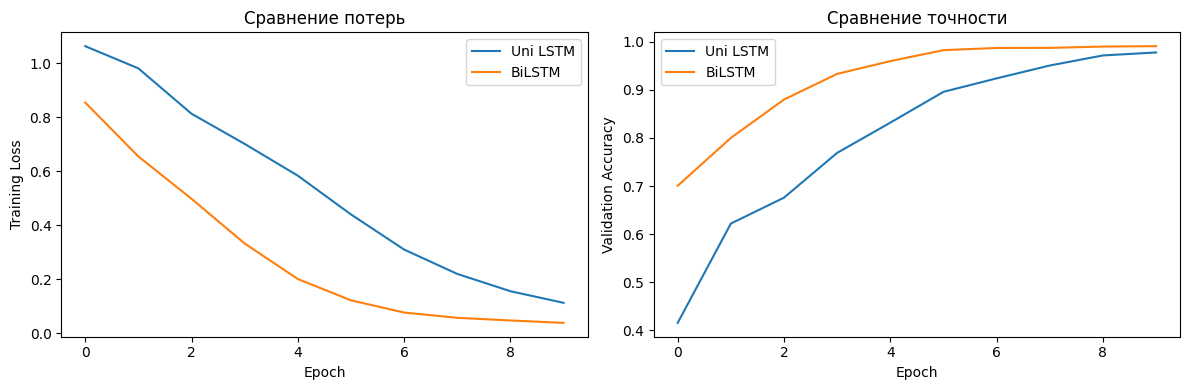

In [17]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

### **3.1. Визуализация скрытых состояний с помощью t-SNE (3 класса)**

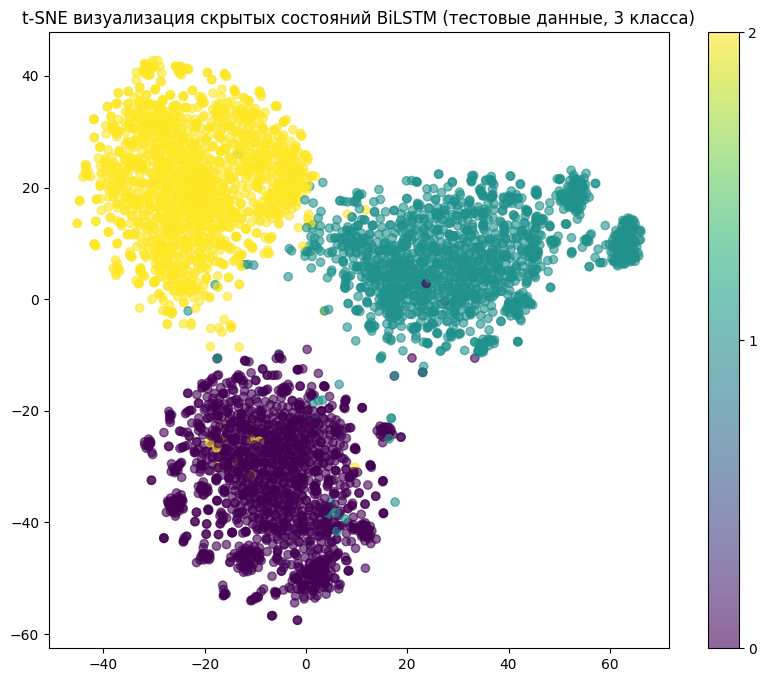

In [18]:
model_bi.eval()
hidden_states = []
labels = []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        embedded = model_bi.embedding(X_batch)
        lstm_out, (hidden, _) = model_bi.lstm(embedded)
        if model_bi.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden_states.append(hidden.cpu().numpy())
        labels.append(y_batch.numpy())

hidden_states = np.vstack(hidden_states)
labels = np.hstack(labels)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
hidden_2d = tsne.fit_transform(hidden_states)

plt.figure(figsize=(10,8))
scatter = plt.scatter(hidden_2d[:,0], hidden_2d[:,1], c=labels, cmap='viridis', alpha=0.6)
plt.colorbar(scatter, ticks=[0,1,2])
plt.title('t-SNE визуализация скрытых состояний BiLSTM (тестовые данные, 3 класса)')
plt.show()

**Задание для интерпретации - ответы**

1. В базовом запуске (hidden size 128, один слой) BiLSTM достигла **0.9909** validation accuracy на 10-й эпохе, однонаправленная LSTM - **0.9778**. Двунаправленная модель использует контекст с обеих сторон последовательности, что помогает классифицировать текст по словам и выражениям, смысл которых зависит от окружения.

2. На t-SNE видны три преимущественные группы скрытых состояний: класс 0 (нейтральный), класс 1 (положительный) и класс 2 (отрицательный). Между группами есть смешанные точки, что согласуется с неоднозначными отзывами или близкими признаками разных тональностей. Проекцию можно использовать для качественного осмотра разделимости классов и поиска пограничных примеров; геометрические расстояния t-SNE не являются метрикой качества классификатора.

3. В дополнительных запусках BiLSTM с hidden size 64 получила соответственно **0.9905** и **0.9869**; с hidden size 256 - **0.9873** и **0.9888**. Ни один вариант не превзошёл базовую BiLSTM. Однонаправленные варианты достигли максимумов 0.9801, 0.9828, 0.9853 и 0.9761 соответственно. Увеличение размера и глубины не дало устойчивого улучшения и увеличило время обучения: BiLSTM с hidden size 256 занимала около 36 секунд на эпоху против примерно 13 секунд у базовой модели.

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 754/754 [00:13<00:00, 57.02it/s, loss=0.945]


Epoch 1: avg_train_loss=0.9965, val_acc=0.6154


Epoch 2/10: 100%|██████████| 754/754 [00:13<00:00, 57.62it/s, loss=0.706]


Epoch 2: avg_train_loss=0.7855, val_acc=0.7034


Epoch 3/10: 100%|██████████| 754/754 [00:13<00:00, 57.69it/s, loss=0.541]


... (31 outputs left out)

Epoch 9/10: 100%|██████████| 754/754 [00:14<00:00, 53.05it/s, loss=0.0248]


Epoch 9: avg_train_loss=0.0578, val_acc=0.9876


Epoch 10/10: 100%|██████████| 754/754 [00:14<00:00, 53.17it/s, loss=0.0627]


Epoch 10: avg_train_loss=0.0458, val_acc=0.9905


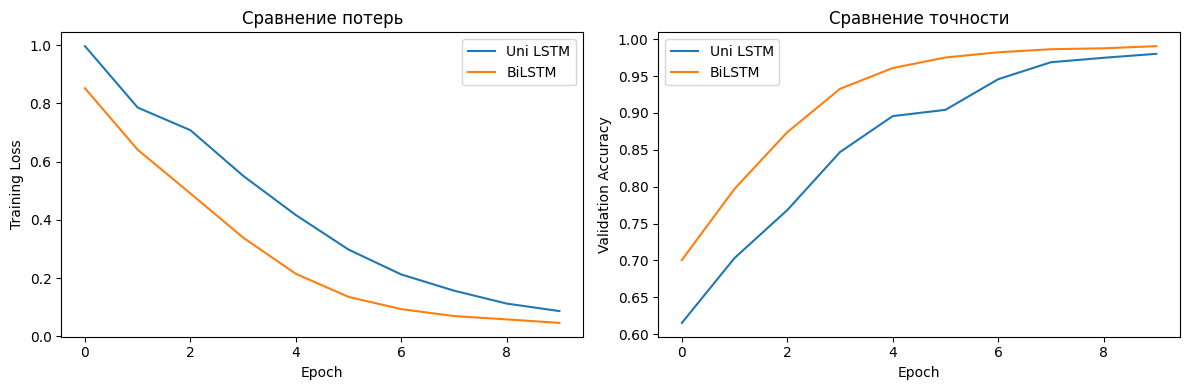

In [19]:
# Параметры
embed_dim = 100
hidden_dim = 64 # было 128
output_dim = 3  # три класса: neutral, positive, negative
n_layers = 2 # было 1

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False, n_layers=n_layers).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True, n_layers=n_layers).to(device)

print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 754/754 [00:13<00:00, 55.20it/s, loss=1.04]


Epoch 1: avg_train_loss=1.0590, val_acc=0.4978


Epoch 2/10: 100%|██████████| 754/754 [00:13<00:00, 55.54it/s, loss=0.774]


Epoch 2: avg_train_loss=0.9276, val_acc=0.5619


Epoch 3/10: 100%|██████████| 754/754 [00:13<00:00, 54.60it/s, loss=0.67]


... (31 outputs left out)

Epoch 9/10: 100%|██████████| 754/754 [00:14<00:00, 50.52it/s, loss=0.00988]


Epoch 9: avg_train_loss=0.0610, val_acc=0.9853


Epoch 10/10: 100%|██████████| 754/754 [00:15<00:00, 50.19it/s, loss=0.0073]


Epoch 10: avg_train_loss=0.0497, val_acc=0.9869


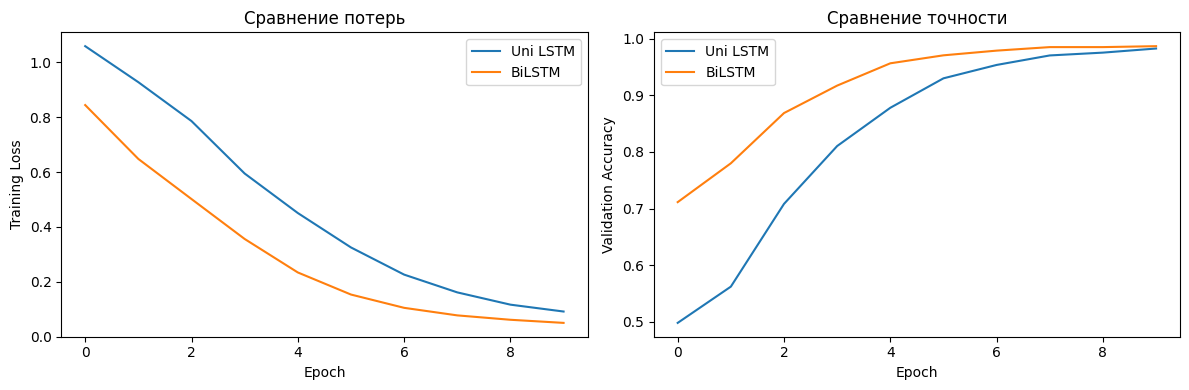

In [20]:
# Параметры
embed_dim = 100
hidden_dim = 64 # было 128
output_dim = 3  # три класса: neutral, positive, negative
n_layers = 3 # было 1

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False, n_layers=n_layers).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True, n_layers=n_layers).to(device)

print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 754/754 [00:17<00:00, 43.32it/s, loss=0.979]


Epoch 1: avg_train_loss=0.9920, val_acc=0.5522


Epoch 2/10: 100%|██████████| 754/754 [00:17<00:00, 43.12it/s, loss=0.847]


Epoch 2: avg_train_loss=0.8213, val_acc=0.6980


Epoch 3/10: 100%|██████████| 754/754 [00:17<00:00, 43.16it/s, loss=0.512]


... (31 outputs left out)

Epoch 9/10: 100%|██████████| 754/754 [00:26<00:00, 28.85it/s, loss=0.000972]


Epoch 9: avg_train_loss=0.0453, val_acc=0.9851


Epoch 10/10: 100%|██████████| 754/754 [00:26<00:00, 28.94it/s, loss=0.012]


Epoch 10: avg_train_loss=0.0351, val_acc=0.9873


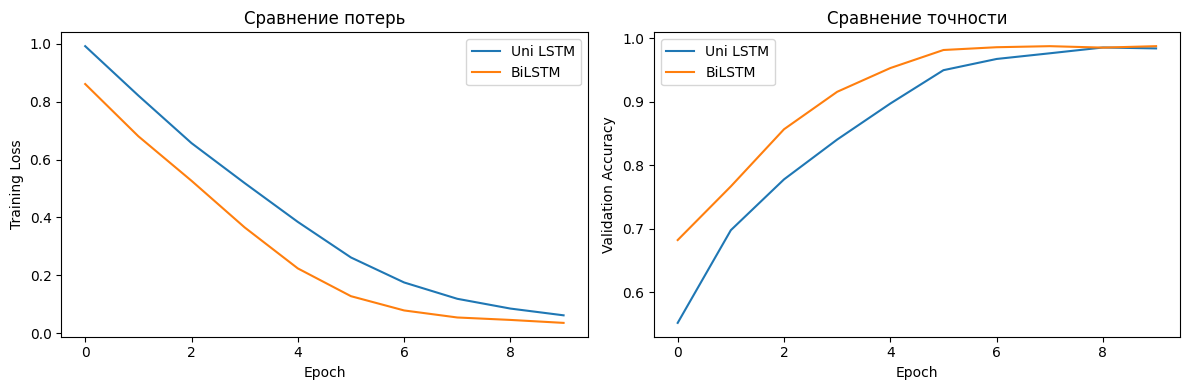

In [21]:
# Параметры
embed_dim = 100
hidden_dim = 256 # было 128
output_dim = 3  # три класса: neutral, positive, negative
n_layers = 2 # было 1

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False, n_layers=n_layers).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True, n_layers=n_layers).to(device)

print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 754/754 [00:20<00:00, 36.61it/s, loss=1.17]


Epoch 1: avg_train_loss=1.0680, val_acc=0.4256


Epoch 2/10: 100%|██████████| 754/754 [00:20<00:00, 36.23it/s, loss=1.12]


Epoch 2: avg_train_loss=1.0719, val_acc=0.4263


Epoch 3/10: 100%|██████████| 754/754 [00:20<00:00, 36.50it/s, loss=0.983]


... (31 outputs left out)

Epoch 9/10: 100%|██████████| 754/754 [00:36<00:00, 20.59it/s, loss=0.213]


Epoch 9: avg_train_loss=0.0626, val_acc=0.9832


Epoch 10/10: 100%|██████████| 754/754 [00:36<00:00, 20.65it/s, loss=0.015]


Epoch 10: avg_train_loss=0.0510, val_acc=0.9888


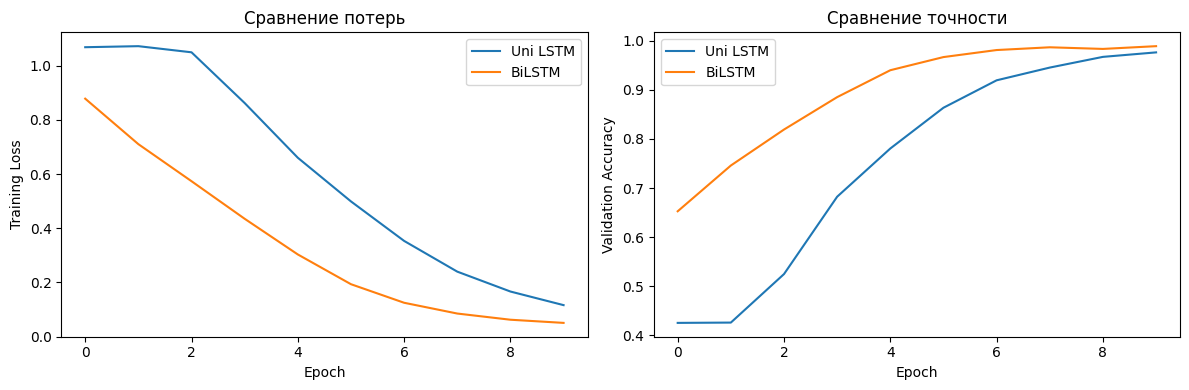

In [22]:
# Параметры
embed_dim = 100
hidden_dim = 256 # было 128
output_dim = 3  # три класса: neutral, positive, negative
n_layers = 3 # было 1

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False, n_layers=n_layers).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True, n_layers=n_layers).to(device)

print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

## **Заключение**

В этом практическом занятии мы:
- Убедились, что LSTM и GRU значительно лучше справляются с долгосрочными зависимостями, чем vanilla RNN.
- Визуализировали градиенты и увидели, что в RNN они быстро затухают.
- Применили BiLSTM для классификации русскоязычных текстов и сравнили с однонаправленной версией.
- Использовали t-SNE для визуализации скрытых представлений.

Попробуйте поэкспериментировать с гиперпараметрами и, возможно, применить предобученные эмбеддинги (FastText) для улучшения качества.

**Новые навыки и знания:** построение последовательных моделей RNN/LSTM/GRU, сравнение обучения на синтетических рядах и классификации текста, а также визуализация скрытых представлений через t-SNE. Для следующих экспериментов полезно фиксировать случайные состояния и сравнивать модели на одной и той же выборке и метрике.